# EDA de viabilidad — Hito 2

Mide las propiedades de calidad de la muestra (`data/muestra/`) y busca *leakage*. Lee los CSV **tal cual**, sin limpiarlos. Cada celda de medición termina imprimiendo una línea `RESULTADO [ID]: ...`, que es la que citan los documentos de `hito-2/`.

Corre de punta a punta con `jupyter nbconvert --to notebook --execute --inplace notebooks/eda_viabilidad.ipynb`. Lo que depende de la red se cachea en `data/cache/`; con la caché presente, no usa la red. Las imágenes del subconjunto se bajan con `scripts/descargar_imagenes.py` (no se commitean); si no están, las celdas que las usan lo dicen y no fallan.

Este notebook solo mide: no entrena, no escala, no imputa y no parte los datos.

## [S0] Setup

In [1]:
import csv
import json
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from io import BytesIO
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from PIL import Image
from sklearn.metrics import cohen_kappa_score

SEMILLA = 42
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MUESTRA = RAIZ / "data" / "muestra"
CACHE = RAIZ / "data" / "cache"
ETIQUETADO = RAIZ / "data" / "etiquetado"
CACHE.mkdir(parents=True, exist_ok=True)

CATEGORIAS = ["tops", "shoes", "pants"]
ATRIBUTOS = {
    "tops": ["neck_style", "fit_silhouette", "season"],
    "shoes": ["wearing_occasion", "style_silhouette", "season"],
    "pants": ["pocket_details", "fit_silhouette", "season"],
}
RESULTADOS = {}

def resultado(clave, texto):
    RESULTADOS[clave] = texto
    print(f"RESULTADO [{clave}]: {texto}")

# Encabezados tal como vienen en el archivo (pandas renombra los duplicados a "x.1").
encabezados = {}
for cat in CATEGORIAS:
    with open(MUESTRA / f"{cat}_tags.csv", newline="", encoding="utf-8") as f:
        encabezados[cat] = next(csv.reader(f))

# Carga tal cual: todo como texto, sin limpiar.
dfs = {cat: pd.read_csv(MUESTRA / f"{cat}_tags.csv", dtype=str) for cat in CATEGORIAS}
taxonomia = {}
for cat in CATEGORIAS:
    meta = json.loads((MUESTRA / "taxonomia" / f"{cat}.labels.json").read_text(encoding="utf-8"))
    taxonomia[cat] = {g["name"]: g["classes"] for g in meta["groups"]}

subconjunto = pd.read_csv(MUESTRA / "subconjunto_imagenes.csv", dtype=str)
subconjunto["existe"] = subconjunto["ruta"].map(lambda r: (RAIZ / r).exists())

for cat in CATEGORIAS:
    dup = [c for c, n in Counter(encabezados[cat]).items() if n > 1]
    print(f"{cat}: {dfs[cat].shape[0]:,} filas · encabezado {encabezados[cat]} · columnas repetidas: {dup or 'ninguna'}")
print(f"Subconjunto de imágenes: {len(subconjunto)} en la lista, {subconjunto['existe'].sum()} descargadas")

tops: 36,173 filas · encabezado ['id', 'image_url', 'neck_style', 'fit_silhouette', 'season', 'relative_path'] · columnas repetidas: ninguna
shoes: 17,281 filas · encabezado ['id', 'image_url', 'wearing_occasion', 'style_silhouette', 'season', 'relative_path', 'relative_path'] · columnas repetidas: ['relative_path']
pants: 7,149 filas · encabezado ['id', 'image_url', 'pocket_details', 'fit_silhouette', 'season', 'relative_path'] · columnas repetidas: ninguna
Subconjunto de imágenes: 300 en la lista, 300 descargadas


## [V1] Volumen

Filas por categoría: {'tops': 36173, 'shoes': 17281, 'pants': 7149} · total: 60,603 · el canvas dice ~50.000


,categoria,atributo,clases,clases_>=100,clases_<100,clases_<30,%_filas_en_clases_>=100,clase_mayor,clase_menor
0,tops,neck_style,31,21,10,6,99.2,"Crew-Neck (8,715)",Illusion-Neck (2)
1,tops,fit_silhouette,7,4,3,2,99.9,"Relaxed-Fit (26,551)",Modern-Fit (2)
2,tops,season,4,4,0,0,100.0,"Spring (12,846)","Cold_Weather-Vacation (1,525)"
3,shoes,wearing_occasion,21,11,10,8,99.4,"Casual (5,976)",Hunting-Outdoor_Activity (1)
4,shoes,style_silhouette,39,21,18,12,96.6,"Boots (2,970)",Dad-Sneakers (1)
5,shoes,season,4,4,0,0,100.0,"Fall (12,629)",Spring (750)
6,pants,pocket_details,14,8,6,4,97.6,"Pockets (2,724)",Inner-Key-Pocket (4)
7,pants,fit_silhouette,11,4,7,6,98.4,"Regular-Fit-Pant (4,218)",Compression (1)
8,pants,season,4,3,1,0,98.7,"Fall (3,871)",Cold_Weather-Vacation (96)


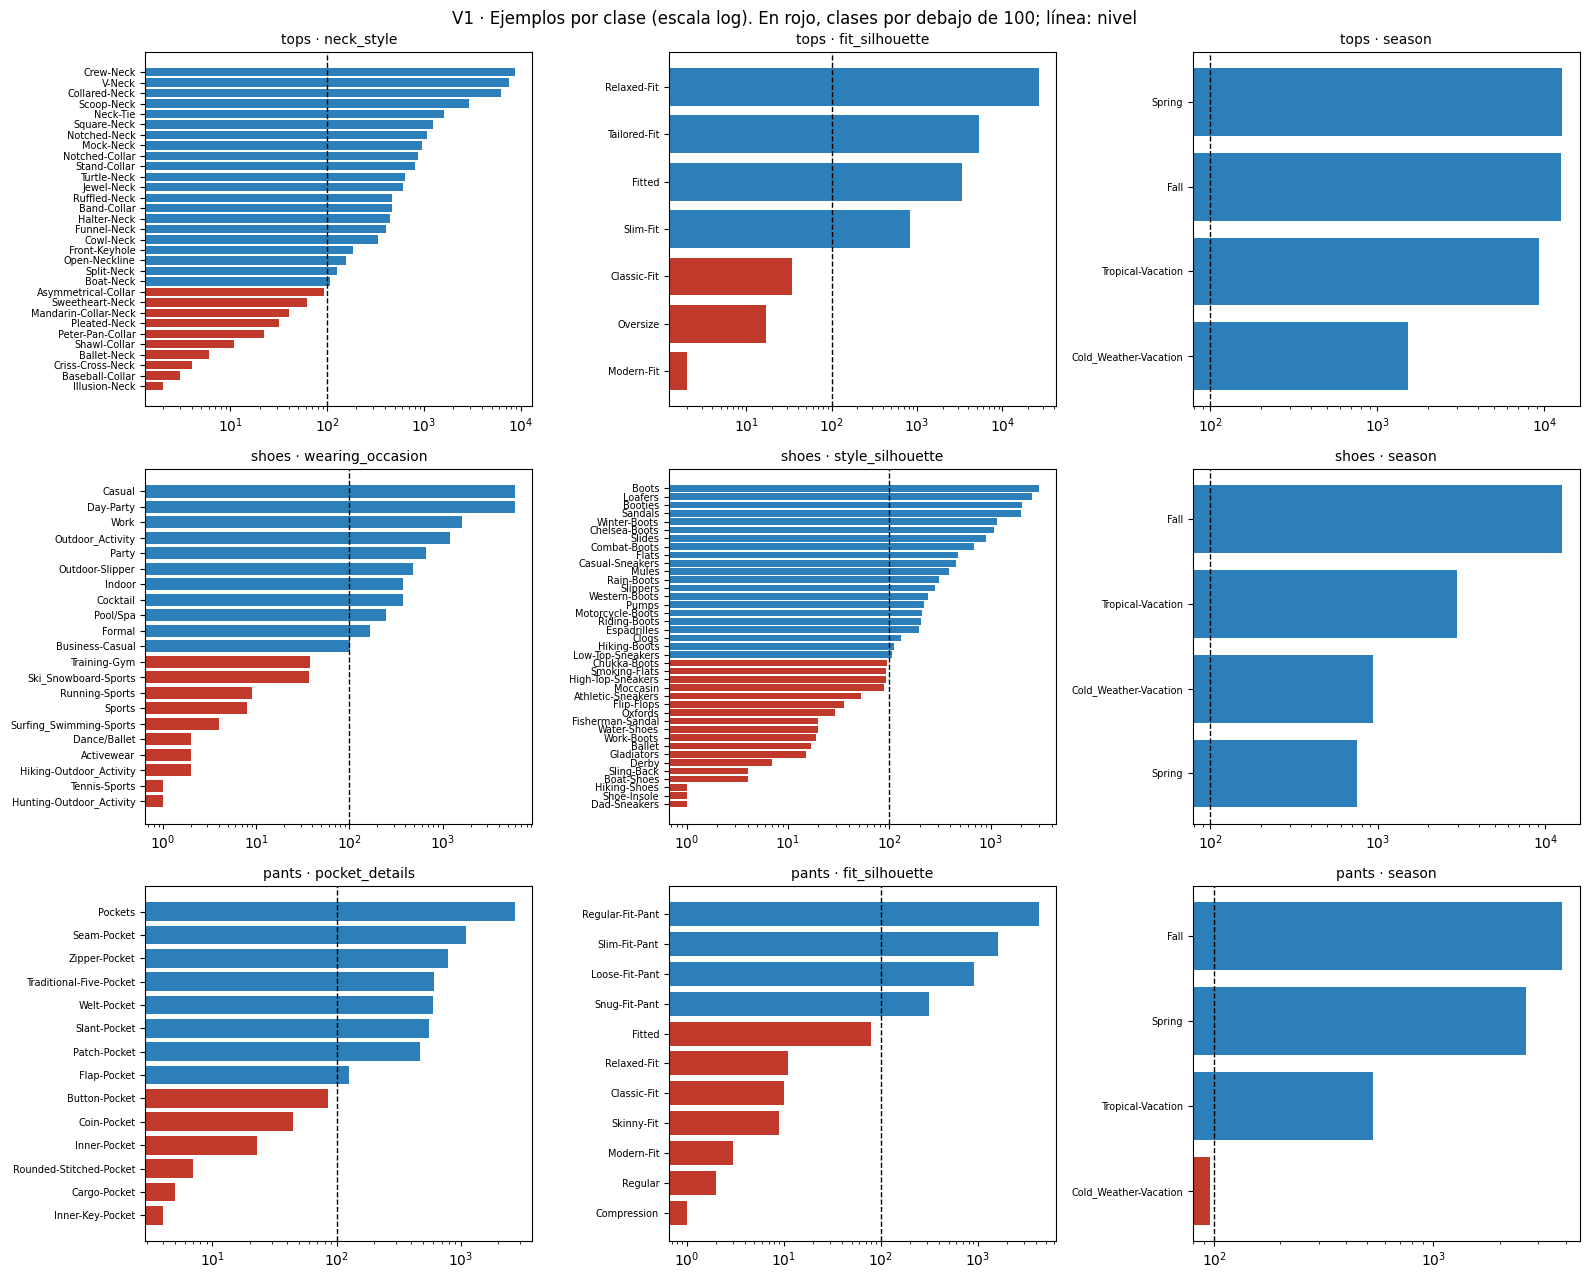

RESULTADO [V1]: 60,603 filas (tops 36,173, shoes 17,281, pants 7,149), contra ~50.000 del canvas. 135 clases en 9 atributos; 80 llegan a 100 y 55 (41 %) tienen menos de 100 ejemplos y 38 menos de 30


In [2]:
NIVEL_CLASE = 100   # ejemplos por clase (nivel de la sección 1 del EDA)
NIVEL_EVAL = 30     # reservables para evaluación

filas = {cat: len(dfs[cat]) for cat in CATEGORIAS}
total = sum(filas.values())
print("Filas por categoría:", filas, "· total:", f"{total:,}", "· el canvas dice ~50.000")

tabla = []
for cat in CATEGORIAS:
    for attr in ATRIBUTOS[cat]:
        conteo = dfs[cat][attr].value_counts(dropna=True)
        tabla.append({
            "categoria": cat, "atributo": attr, "clases": len(conteo),
            "clases_>=100": int((conteo >= NIVEL_CLASE).sum()),
            "clases_<100": int((conteo < NIVEL_CLASE).sum()),
            "clases_<30": int((conteo < NIVEL_EVAL).sum()),
            "%_filas_en_clases_>=100": round(100 * conteo[conteo >= NIVEL_CLASE].sum() / conteo.sum(), 1),
            "clase_mayor": f"{conteo.index[0]} ({conteo.iloc[0]:,})",
            "clase_menor": f"{conteo.index[-1]} ({conteo.iloc[-1]:,})",
        })
tabla_v1 = pd.DataFrame(tabla)
display(tabla_v1)

fig, ejes = plt.subplots(3, 3, figsize=(16, 13))
for i, cat in enumerate(CATEGORIAS):
    for j, attr in enumerate(ATRIBUTOS[cat]):
        ax = ejes[i, j]
        conteo = dfs[cat][attr].value_counts().sort_values()
        colores = ["#c0392b" if v < NIVEL_CLASE else "#2c7fb8" for v in conteo.values]
        ax.barh(conteo.index, conteo.values, color=colores)
        ax.axvline(NIVEL_CLASE, color="black", ls="--", lw=1)
        ax.set_xscale("log")
        ax.set_title(f"{cat} · {attr}", fontsize=10)
        ax.tick_params(axis="y", labelsize=7)
fig.suptitle("V1 · Ejemplos por clase (escala log). En rojo, clases por debajo de 100; línea: nivel", fontsize=12)
plt.tight_layout()
plt.show()

clases = tabla_v1["clases"].sum()
debajo = tabla_v1["clases_<100"].sum()
resultado("V1", f"{total:,} filas ({', '.join(f'{c} {n:,}' for c, n in filas.items())}), contra ~50.000 del canvas. "
               f"{clases} clases en 9 atributos; {clases - debajo} llegan a 100 y {debajo} ({100*debajo/clases:.0f} %) tienen menos de 100 ejemplos "
               f"y {tabla_v1['clases_<30'].sum()} menos de 30")

## [C2] Completitud

In [3]:
# 1) Faltantes por columna y por categoría (vacío en el CSV = faltante).
faltantes = []
for cat in CATEGORIAS:
    df = dfs[cat]
    for col in df.columns:
        n = int(df[col].isna().sum())
        faltantes.append({"categoria": cat, "columna": col, "faltantes": n, "%_presente": round(100 * (1 - n / len(df)), 2)})
faltantes = pd.DataFrame(faltantes)
display(faltantes.pivot(index="columna", columns="categoria", values="%_presente"))
etiquetas = faltantes[faltantes["columna"].isin({a for v in ATRIBUTOS.values() for a in v})]
min_etiqueta = etiquetas["%_presente"].min()

# 2) Completitud estructural: atributos que el producto devuelve (canvas §3) y no existen como columna.
NECESARIOS = {"tipo de prenda": ["product_type", "article_type", "type", "category"],
              "color": ["color", "colour", "base_colour"],
              "material": ["material", "fabric"],
              "título": ["title", "name"],
              "descripción": ["description"],
              "fecha": ["date", "created_at", "published_at"]}
todas = {c.lower() for df in dfs.values() for c in df.columns}
estructural = {k: any(c in todas for c in v) for k, v in NECESARIOS.items()}
print("¿Existe la columna?", estructural)

categoria,pants,shoes,tops
columna,,,
fit_silhouette,100.00,NaN,100.00
id,100.00,100.0,100.00
image_url,100.00,100.0,100.00
neck_style,NaN,NaN,100.00
pocket_details,100.00,NaN,NaN
relative_path,99.97,100.0,99.99
relative_path.1,NaN,100.0,NaN
season,100.00,100.0,100.00
style_silhouette,NaN,100.0,NaN


¿Existe la columna? {'tipo de prenda': False, 'color': False, 'material': False, 'título': False, 'descripción': False, 'fecha': False}


In [4]:
# 3) Chequeo de URLs: 500 por categoría, semilla fija, con caché.
CACHE_URL = CACHE / "url_check.csv"
N_URL = 500
HEADERS = {"User-Agent": "UdeSA-toi-hito2/1.0 (trabajo academico)", "Range": "bytes=0-65535"}

def chequear(fila):
    salida = {"id": fila.id, "categoria": fila.categoria, "image_url": fila.image_url}
    try:
        r = requests.get(fila.image_url, headers=HEADERS, timeout=20)
        salida.update(status=r.status_code, content_type=r.headers.get("Content-Type"),
                      last_modified=r.headers.get("Last-Modified"))
        try:
            img = Image.open(BytesIO(r.content))      # lee el encabezado de la imagen
            salida.update(abre_imagen=True, formato=img.format, ancho=img.size[0], alto=img.size[1])
        except Exception:
            salida.update(abre_imagen=False)
    except requests.RequestException as e:
        salida.update(status=None, error=e.__class__.__name__, abre_imagen=False)
    time.sleep(0.2)
    return salida

if CACHE_URL.exists():
    url_check = pd.read_csv(CACHE_URL, dtype={"id": str})
    print(f"Caché: {CACHE_URL.relative_to(RAIZ)} ({len(url_check)} filas, chequeadas el {url_check['fecha_chequeo'].iloc[0]})")
else:
    elegidas = pd.concat([dfs[c].sample(n=min(N_URL, len(dfs[c])), random_state=SEMILLA)[["id", "image_url"]]
                          .assign(categoria=c) for c in CATEGORIAS])
    with ThreadPoolExecutor(max_workers=6) as pool:
        url_check = pd.DataFrame(pool.map(chequear, elegidas.itertuples()))
    url_check["fecha_chequeo"] = datetime.now(timezone.utc).date().isoformat()
    url_check.to_csv(CACHE_URL, index=False)
    print(f"Chequeadas {len(url_check)} URLs y guardadas en {CACHE_URL.relative_to(RAIZ)}")

url_check["ok"] = url_check["status"].isin([200, 206]) & url_check["abre_imagen"].astype(bool)
resumen_url = url_check.groupby("categoria")["ok"].agg(["sum", "count", "mean"]).rename(columns={"mean": "proporcion_ok"})
display(resumen_url)
display(url_check["status"].value_counts(dropna=False).rename("status HTTP"))
pct_url = 100 * url_check["ok"].mean()

faltan = [k for k, v in estructural.items() if not v]
resultado("C2", f"columnas de etiqueta: mínimo {min_etiqueta:.2f} % de valores presentes. "
               f"No existen como columna: {', '.join(faltan)}. "
               f"URLs: {url_check['ok'].sum()} de {len(url_check)} ({pct_url:.1f} %) responden y abren como imagen")

Caché: data\cache\url_check.csv (1500 filas, chequeadas el 2026-10-20)


,sum,count,proporcion_ok
categoria,,,
pants,500,500,1.0
shoes,500,500,1.0
tops,500,500,1.0


status
206    1500
Name: status HTTP, dtype: int64

RESULTADO [C2]: columnas de etiqueta: mínimo 100.00 % de valores presentes. No existen como columna: tipo de prenda, color, material, título, descripción, fecha. URLs: 1500 de 1500 (100.0 %) responden y abren como imagen


## [C3] Corrección

In [5]:
filas_c3 = []
# Duplicados exactos
for cat in CATEGORIAS:
    df = dfs[cat]
    filas_c3.append({"categoria": cat,
                     "id_duplicados": int(df["id"].duplicated().sum()),
                     "url_duplicadas": int(df["image_url"].duplicated().sum()),
                     "filas_duplicadas": int(df.duplicated().sum()),
                     "columnas_repetidas_en_encabezado": ", ".join(c for c, n in Counter(encabezados[cat]).items() if n > 1) or "-"})
display(pd.DataFrame(filas_c3))

# Valores fuera de la taxonomía (clases del labels.json del modelo, que solo guarda clases con >= 20 ejemplos)
fuera = []
for cat in CATEGORIAS:
    for attr in ATRIBUTOS[cat]:
        conteo = dfs[cat][attr].value_counts()
        no_tax = conteo[~conteo.index.isin(taxonomia[cat][attr])]
        fuera.append({"categoria": cat, "atributo": attr, "valores_fuera": len(no_tax),
                      "filas_fuera": int(no_tax.sum()), "%_filas": round(100 * no_tax.sum() / conteo.sum(), 2),
                      "max_filas_de_un_valor_fuera": int(no_tax.max()) if len(no_tax) else 0,
                      "ejemplos": ", ".join(no_tax.index[:4])})
fuera = pd.DataFrame(fuera)
display(fuera)
filas_fuera_total = fuera["filas_fuera"].sum()

# Formato: mezcla de "_" y "-", espacios, variantes de mayúsculas del mismo valor
formato = []
for cat in CATEGORIAS:
    for attr in ATRIBUTOS[cat]:
        valores = dfs[cat][attr].dropna().unique()
        mezcla = [v for v in valores if "_" in v and "-" in v]
        espacios = [v for v in valores if v != v.strip() or " " in v]
        norm = Counter(re.sub(r"[-_ ]", "", v).lower() for v in valores)
        variantes = [k for k, n in norm.items() if n > 1]
        formato.append({"categoria": cat, "atributo": attr, "mezcla_guion_y_guion_bajo": ", ".join(mezcla) or "-",
                        "con_espacios": len(espacios), "variantes_del_mismo_valor": len(variantes)})
formato = pd.DataFrame(formato)
display(formato)
valores_mezcla = sorted({v for x in formato["mezcla_guion_y_guion_bajo"] if x != "-" for v in x.split(", ")})
print("Valores con '_' y '-' mezclados:", valores_mezcla)

# Artefacto: las dos columnas relative_path de shoes, ¿son iguales?
sh = dfs["shoes"]
iguales = (sh["relative_path"].fillna("") == sh["relative_path.1"].fillna("")).mean()
print(f"shoes: las dos columnas relative_path coinciden en {100*iguales:.1f} % de las filas")

,categoria,id_duplicados,url_duplicadas,filas_duplicadas,columnas_repetidas_en_encabezado
0,tops,0,1,0,-
1,shoes,0,0,0,relative_path
2,pants,0,0,0,-


,categoria,atributo,valores_fuera,filas_fuera,%_filas,max_filas_de_un_valor_fuera,ejemplos
0,tops,neck_style,5,26,0.07,11,"Shawl-Collar, Ballet-Neck, Criss-Cross-Neck, B..."
1,tops,fit_silhouette,2,19,0.05,17,"Oversize, Modern-Fit"
2,tops,season,0,0,0.00,0,
3,shoes,wearing_occasion,8,29,0.17,9,"Running-Sports, Sports, Surfing_Swimming-Sport..."
4,shoes,style_silhouette,9,69,0.40,19,"Work-Boots, Ballet, Gladiators, Derby"
5,shoes,season,0,0,0.00,0,
6,pants,pocket_details,3,16,0.22,7,"Rounded-Stitched-Pocket, Cargo-Pocket, Inner-K..."
7,pants,fit_silhouette,6,36,0.50,11,"Relaxed-Fit, Classic-Fit, Skinny-Fit, Modern-Fit"
8,pants,season,0,0,0.00,0,


,categoria,atributo,mezcla_guion_y_guion_bajo,con_espacios,variantes_del_mismo_valor
0,tops,neck_style,-,0,0
1,tops,fit_silhouette,-,0,0
2,tops,season,Cold_Weather-Vacation,0,0
3,shoes,wearing_occasion,"Ski_Snowboard-Sports, Surfing_Swimming-Sports,...",0,0
4,shoes,style_silhouette,-,0,0
5,shoes,season,Cold_Weather-Vacation,0,0
6,pants,pocket_details,-,0,0
7,pants,fit_silhouette,-,0,0
8,pants,season,Cold_Weather-Vacation,0,0


Valores con '_' y '-' mezclados: ['Cold_Weather-Vacation', 'Hiking-Outdoor_Activity', 'Hunting-Outdoor_Activity', 'Ski_Snowboard-Sports', 'Surfing_Swimming-Sports']
shoes: las dos columnas relative_path coinciden en 100.0 % de las filas


In [6]:
# Imágenes del subconjunto descargado: abren, tamaño, duplicados casi exactos (pHash, Hamming <= 4)
bajadas = subconjunto[subconjunto["existe"]].copy()
if len(bajadas):
    info = []
    for f in bajadas.itertuples():
        try:
            with Image.open(RAIZ / f.ruta) as img:
                img.load()
                info.append({"id": f.id, "categoria": f.categoria, "abre": True, "ancho": img.size[0],
                             "alto": img.size[1], "modo": img.mode, "phash": imagehash.phash(img.convert("RGB"))})
        except Exception:
            info.append({"id": f.id, "categoria": f.categoria, "abre": False})
    info = pd.DataFrame(info)
    ok = info[info["abre"]]
    tamanos = ok.groupby(["ancho", "alto"]).size().sort_values(ascending=False)
    print("Tamaños de imagen (ancho x alto: cantidad):", tamanos.head(5).to_dict())
    anomalas = ok[(ok[["ancho", "alto"]].min(axis=1) < 224) | ((ok["ancho"] / ok["alto"]) > 2) | ((ok["alto"] / ok["ancho"]) > 2)]
    hashes = list(ok["phash"])
    pares = []
    for i in range(len(hashes)):
        for j in range(i + 1, len(hashes)):
            d = hashes[i] - hashes[j]
            if d <= 4:
                pares.append({"id_a": ok["id"].iloc[i], "cat_a": ok["categoria"].iloc[i],
                              "id_b": ok["id"].iloc[j], "cat_b": ok["categoria"].iloc[j], "distancia": d})
    pares = pd.DataFrame(pares, columns=["id_a", "cat_a", "id_b", "cat_b", "distancia"])
    display(pares)
    ids_en_pares = set(pares["id_a"]) | set(pares["id_b"])
    pct_dup_img = 100 * len(ids_en_pares) / len(ok)
    texto_img = (f"subconjunto de {len(info)} imágenes: {(~info['abre']).sum()} no abren, {len(anomalas)} con tamaño anómalo, "
                 f"{len(pares)} pares candidatos a casi duplicados (pHash ≤ 4) que involucran {len(ids_en_pares)} imágenes ({pct_dup_img:.1f} %), "
                 f"todos de {ok['ancho'].iloc[0]}x{ok['alto'].iloc[0]} px" if ok[['ancho','alto']].nunique().max() == 1 else "")
else:
    info, pares, texto_img = pd.DataFrame(), pd.DataFrame(), "sin imágenes descargadas (correr scripts/descargar_imagenes.py)"
print(texto_img)

# Cotejo con el consenso humano (sale de R6; si no hay re-etiquetado, queda pendiente)
cotejo = "sin re-etiquetado todavía (ver R6)"
dup = pd.DataFrame(filas_c3)
todas_urls = pd.concat([d["image_url"] for d in dfs.values()])
url_rep = int(todas_urls.duplicated().sum())
resultado("C3", f"duplicados exactos: {dup['id_duplicados'].sum()} de id, {dup['url_duplicadas'].sum()} de URL dentro de una categoría "
               f"y {url_rep} en total contando entre categorías ({100*url_rep/len(todas_urls):.2f} % de las filas), {dup['filas_duplicadas'].sum()} filas duplicadas. "
               f"Encabezado de shoes con relative_path repetida. "
               f"Valores fuera de la taxonomía del modelo: {filas_fuera_total:,} filas "
               f"({100*filas_fuera_total/sum(len(d) for d in dfs.values())/3:.2f} % de los valores de etiqueta). "
               f"{len(valores_mezcla)} valores distintos mezclan '_' y '-' (p. ej. {valores_mezcla[0]}). Imágenes: {texto_img}. "
               f"Cotejo contra la foto: {cotejo}")

Tamaños de imagen (ancho x alto: cantidad): {(1056, 1320): 300}


,id_a,cat_a,id_b,cat_b,distancia
0,11908154,tops,12990589,tops,4
1,12846334,shoes,14455910,shoes,4
2,19208937,shoes,19432546,shoes,4


subconjunto de 300 imágenes: 0 no abren, 0 con tamaño anómalo, 3 pares candidatos a casi duplicados (pHash ≤ 4) que involucran 6 imágenes (2.0 %), todos de 1056x1320 px
RESULTADO [C3]: duplicados exactos: 0 de id, 1 de URL dentro de una categoría y 167 en total contando entre categorías (0.28 % de las filas), 0 filas duplicadas. Encabezado de shoes con relative_path repetida. Valores fuera de la taxonomía del modelo: 195 filas (0.11 % de los valores de etiqueta). 5 valores distintos mezclan '_' y '-' (p. ej. Cold_Weather-Vacation). Imágenes: subconjunto de 300 imágenes: 0 no abren, 0 con tamaño anómalo, 3 pares candidatos a casi duplicados (pHash ≤ 4) que involucran 6 imágenes (2.0 %), todos de 1056x1320 px. Cotejo contra la foto: sin re-etiquetado todavía (ver R6)


**Revisión manual de los pares pHash (2026-10-20).** Los pares que marca pHash ≤ 4 se miraron a mano: son productos distintos fotografiados con la misma pose y el mismo encuadre (fondo blanco, modelo cortada a la altura de la cara, o calzado de perfil). Con fotos de catálogo estandarizadas, pHash a esa distancia da falsos positivos. El número de C3 y L3 es una **cota superior** de duplicados casi exactos, no duplicados confirmados.

## [T4] Vigencia

Respuestas con Last-Modified: 1500 de 1500


lm
2018      4
2019      3
2020      2
2021     24
2022     88
2023    356
2024    386
2025    476
2026    161
Name: imágenes por año de Last-Modified, dtype: int64

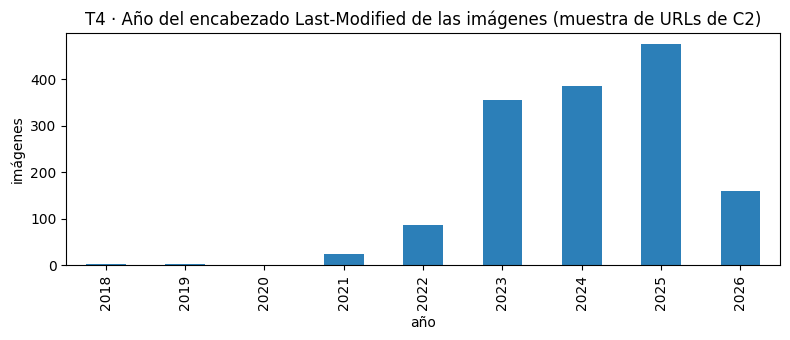

RESULTADO [T4]: no hay columna de fecha. Last-Modified del CDN en 1500 de 1500 URLs: de 2018-02-14 a 2026-10-19; 99.4 % de 2021 en adelante (estimado: es la fecha del archivo en el CDN, no la de publicación)


In [7]:
def fecha(s):
    try:
        return parsedate_to_datetime(s)
    except Exception:
        return pd.NaT

url_check["lm"] = pd.to_datetime(url_check["last_modified"].map(fecha), utc=True)
con_fecha = url_check["lm"].notna()
print(f"Respuestas con Last-Modified: {con_fecha.sum()} de {len(url_check)}")
if con_fecha.any():
    anios = url_check.loc[con_fecha, "lm"].dt.year
    por_anio = anios.value_counts().sort_index()
    display(por_anio.rename("imágenes por año de Last-Modified"))
    ax = por_anio.plot.bar(figsize=(8, 3.5), color="#2c7fb8")
    ax.set_title("T4 · Año del encabezado Last-Modified de las imágenes (muestra de URLs de C2)")
    ax.set_xlabel("año"); ax.set_ylabel("imágenes")
    plt.tight_layout(); plt.show()
    pct_2021 = 100 * (anios >= 2021).mean()
    rango = f"{url_check.loc[con_fecha, 'lm'].min().date()} a {url_check.loc[con_fecha, 'lm'].max().date()}"
    resultado("T4", f"no hay columna de fecha. Last-Modified del CDN en {con_fecha.sum()} de {len(url_check)} URLs: "
                   f"de {rango}; {pct_2021:.1f} % de 2021 en adelante (estimado: es la fecha del archivo en el CDN, no la de publicación)")
else:
    resultado("T4", "no hay columna de fecha y el CDN no devuelve Last-Modified: vigencia sin medir")

## [P5] Representatividad

,categoria,%_de_la_muestra,cumple_>=10%
0,remeras/tops,59.7,True
1,pantalones,11.8,True
2,calzado,28.5,True
3,vestidos,0.0,False
4,abrigos,0.0,False


,tops,shoes,pants
season,,,
Spring,35.5,4.3,37.1
Fall,34.6,73.1,54.1
Tropical-Vacation,25.6,17.2,7.4
Cold_Weather-Vacation,4.2,5.4,1.3


0
asset1.ruecdn.com    60602
asset2.ruecdn.com        1
Name: dominio de las imágenes, dtype: int64

0
RLLDTH    60543
RLLZ          1
Name: código en el nombre de archivo, dtype: int64

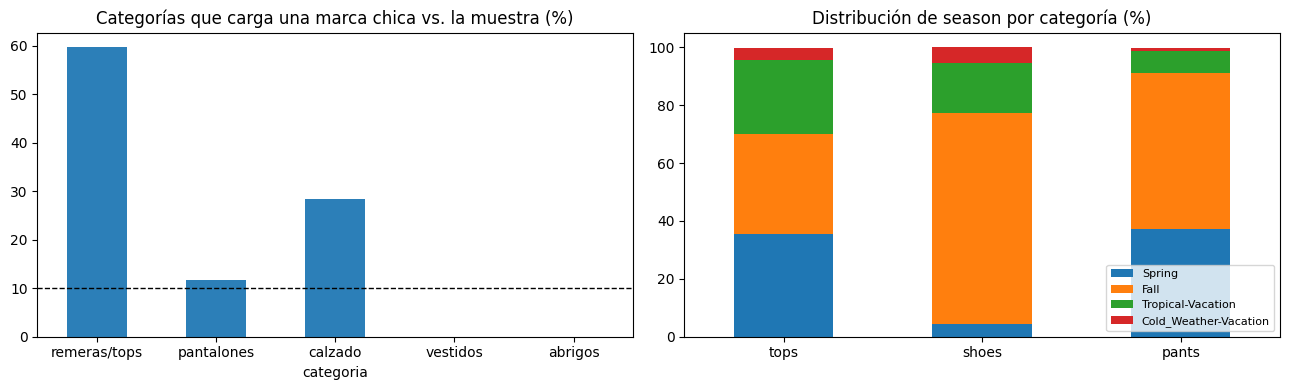

RESULTADO [P5]: 3 categorías: tops 59.7 %, shoes 28.5 %, pants 11.8 %. Faltan: vestidos, abrigos. season: Spring, Fall, Tropical-Vacation, Cold_Weather-Vacation (calendario del hemisferio norte). Dominio de las imágenes: asset1.ruecdn.com (60,602), asset2.ruecdn.com (1)


In [8]:
comp = pd.Series({c: len(dfs[c]) for c in CATEGORIAS})
pct_comp = (100 * comp / comp.sum()).round(1)
necesarias = ["remeras/tops", "pantalones", "calzado", "vestidos", "abrigos"]
presentes = {"remeras/tops": "tops", "pantalones": "pants", "calzado": "shoes"}
tabla_p5 = pd.DataFrame({"categoria": necesarias,
                         "%_de_la_muestra": [pct_comp.get(presentes.get(n), 0.0) for n in necesarias]})
tabla_p5["cumple_>=10%"] = tabla_p5["%_de_la_muestra"] >= 10
display(tabla_p5)

season = pd.concat([dfs[c]["season"].value_counts().rename(c) for c in CATEGORIAS], axis=1).fillna(0).astype(int)
season_pct = (100 * season / season.sum()).round(1)
display(season_pct)

dominios = pd.concat([d["image_url"] for d in dfs.values()]).str.extract(r"https?://([^/]+)/")[0].value_counts()
display(dominios.rename("dominio de las imágenes"))
codigo = pd.concat([d["image_url"] for d in dfs.values()]).str.extract(r"_([A-Z]+)_\d+\.\w+$")[0].value_counts()
display(codigo.rename("código en el nombre de archivo"))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
tabla_p5.set_index("categoria")["%_de_la_muestra"].plot.bar(ax=ejes[0], color="#2c7fb8")
ejes[0].axhline(10, color="black", ls="--", lw=1); ejes[0].set_title("Categorías que carga una marca chica vs. la muestra (%)")
ejes[0].tick_params(axis="x", rotation=0)
season_pct.T.plot.bar(stacked=True, ax=ejes[1]); ejes[1].set_title("Distribución de season por categoría (%)")
ejes[1].tick_params(axis="x", rotation=0); ejes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

faltan_cat = tabla_p5.loc[~tabla_p5["cumple_>=10%"], "categoria"].tolist()
resultado("P5", f"3 categorías: {', '.join(f'{c} {p} %' for c, p in pct_comp.items())}. Faltan: {', '.join(faltan_cat)}. "
               f"season: {', '.join(season.index)} (calendario del hemisferio norte). "
               f"Dominio de las imágenes: {', '.join(f'{d} ({n:,})' for d, n in dominios.items())}")

## [R6] Confiabilidad

In [9]:
# Consistencia interna (proxy, siempre disponible): fotos que están a la vez en tops y en pants
# tienen dos etiquetas de season para la misma imagen. Si el etiquetado fuera consistente, coincidirían.
t = dfs["tops"][["image_url", "season"]].dropna()
p = dfs["pants"][["image_url", "season"]].dropna()
compartidas = t.merge(p, on="image_url", suffixes=("_tops", "_pants"))
coinc = (compartidas["season_tops"] == compartidas["season_pants"]).mean()
print(f"Fotos con season en tops y en pants: {len(compartidas)}; season coincide en {coinc:.1%}")
display(pd.crosstab(compartidas["season_tops"], compartidas["season_pants"]))
texto_proxy = f"consistencia interna: en {len(compartidas)} fotos etiquetadas en tops y en pants, season coincide en {coinc:.1%}"

archivo_a, archivo_b = ETIQUETADO / "etiquetador_A.csv", ETIQUETADO / "etiquetador_B.csv"
if archivo_a.exists() and archivo_b.exists():
    A = pd.read_csv(archivo_a, dtype=str).set_index("id")
    B = pd.read_csv(archivo_b, dtype=str).set_index("id")
    comunes = A.index.intersection(B.index)
    filas_r6 = []
    originales = pd.concat([dfs[c].assign(categoria=c) for c in CATEGORIAS]).drop_duplicates("id").set_index("id")
    for cat in CATEGORIAS:
        for attr in ATRIBUTOS[cat]:
            ids = [i for i in comunes if A.loc[i, "categoria"] == cat]
            a, b = A.loc[ids, attr], B.loc[ids, attr]
            validos = a.notna() & b.notna()
            if validos.sum() == 0:
                continue
            acuerdo = (a[validos] == b[validos]).mean()
            kappa = cohen_kappa_score(a[validos], b[validos])
            consenso = a[validos][a[validos] == b[validos]]
            vs_orig = (originales.loc[consenso.index, attr] == consenso).mean() if len(consenso) else np.nan
            filas_r6.append({"categoria": cat, "atributo": attr, "n": int(validos.sum()), "acuerdo_A_B": round(acuerdo, 3),
                             "kappa": round(kappa, 3), "original_vs_consenso": round(vs_orig, 3)})
    r6 = pd.DataFrame(filas_r6)
    display(r6)
    for col in ["tipo_foto", "color_principal", "coincide_categoria"]:
        if col in A.columns:
            display(A.loc[comunes, col].value_counts(normalize=True).round(3).rename(f"{col} (etiquetador A)"))
    resultado("R6", f"{len(comunes)} imágenes re-etiquetadas por dos personas. Acuerdo A-B entre {r6['acuerdo_A_B'].min():.0%} y "
                   f"{r6['acuerdo_A_B'].max():.0%}; κ entre {r6['kappa'].min():.2f} y {r6['kappa'].max():.2f}; "
                   f"original vs. consenso entre {r6['original_vs_consenso'].min():.0%} y {r6['original_vs_consenso'].max():.0%}")
else:
    resultado("R6", "sin re-etiquetado, ver estimación (faltan data/etiquetado/etiquetador_A.csv y etiquetador_B.csv). "
                   f"Proxy medido: {texto_proxy}")

Fotos con season en tops y en pants: 166; season coincide en 77.1%


season_pants,Cold_Weather-Vacation,Fall,Spring,Tropical-Vacation
season_tops,,,,
Cold_Weather-Vacation,10,1,1,0
Fall,0,24,10,0
Spring,0,8,70,0
Tropical-Vacation,0,2,16,24


RESULTADO [R6]: sin re-etiquetado, ver estimación (faltan data/etiquetado/etiquetador_A.csv y etiquetador_B.csv). Proxy medido: consistencia interna: en 166 fotos etiquetadas en tops y en pants, season coincide en 77.1%


## [L1] *Leakage*: la definición

In [10]:
# Momento de predecir: el usuario sube la foto. Para cada columna, ¿existe en ese momento?
rol = {
    "id": ("identificador interno del catálogo de origen", "no (el usuario no lo tiene)", "no usar como feature"),
    "image_url": ("ubicación de la imagen en el CDN de origen", "la imagen sí; la URL no", "riesgo: la ruta trae número de producto y código de retailer"),
    "relative_path": ("artefacto del pipeline (ruta local de la descarga)", "no", "no usar: se arma con el id"),
    "relative_path.1": ("copia repetida de relative_path", "no", "no usar"),
}
filas_l1 = []
for cat in CATEGORIAS:
    for col in dfs[cat].columns:
        if col in ATRIBUTOS[cat]:
            filas_l1.append({"categoria": cat, "columna": col, "qué es": "etiqueta (lo que se predice)",
                             "¿existe al predecir?": "no (es el objetivo)", "riesgo": "-"})
        else:
            r = rol[col]
            filas_l1.append({"categoria": cat, "columna": col, "qué es": r[0], "¿existe al predecir?": r[1], "riesgo": r[2]})
l1 = pd.DataFrame(filas_l1)
display(l1)

# ¿La URL o el id codifican la etiqueta? Información de la carpeta de la URL sobre season (por categoría)
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    n = tabla.values.sum()
    esperado = np.outer(tabla.sum(1), tabla.sum(0)) / n
    chi2 = ((tabla.values - esperado) ** 2 / esperado).sum()
    k = min(tabla.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else np.nan

print("title/description en los CSV:", {c: [x for x in ("title", "description") if x in dfs[c].columns] for c in CATEGORIAS})
urls = pd.concat([d["image_url"] for d in dfs.values()])
color_en_url = urls.str.extract(r"_[A-Z]+_([a-z]+)_\d+\.\w+$")[0]
print(f"URLs con un color en el nombre del archivo: {color_en_url.notna().sum()} ->", color_en_url.value_counts().to_dict())
n_etq = int(l1["qué es"].str.startswith("etiqueta").sum())
resultado("L1", f"{len(l1)} columnas en las 3 categorías: {n_etq} etiquetas; id y relative_path (más su copia en shoes) no existen "
               f"al predecir; de image_url, al predecir existe la imagen pero no la ruta, y {color_en_url.notna().sum()} rutas traen el color "
               "en el nombre del archivo. No hay title ni description (describer.py no se corrió); si se generan, salen de los tags (ver L5)")

,categoria,columna,qué es,¿existe al predecir?,riesgo
0,tops,id,identificador interno del catálogo de origen,no (el usuario no lo tiene),no usar como feature
1,tops,image_url,ubicación de la imagen en el CDN de origen,la imagen sí; la URL no,riesgo: la ruta trae número de producto y códi...
2,tops,neck_style,etiqueta (lo que se predice),no (es el objetivo),-
3,tops,fit_silhouette,etiqueta (lo que se predice),no (es el objetivo),-
4,tops,season,etiqueta (lo que se predice),no (es el objetivo),-
5,tops,relative_path,artefacto del pipeline (ruta local de la desca...,no,no usar: se arma con el id
6,shoes,id,identificador interno del catálogo de origen,no (el usuario no lo tiene),no usar como feature
7,shoes,image_url,ubicación de la imagen en el CDN de origen,la imagen sí; la URL no,riesgo: la ruta trae número de producto y códi...
8,shoes,wearing_occasion,etiqueta (lo que se predice),no (es el objetivo),-
9,shoes,style_silhouette,etiqueta (lo que se predice),no (es el objetivo),-


title/description en los CSV: {'tops': [], 'shoes': [], 'pants': []}
URLs con un color en el nombre del archivo: 58 -> {'black': 18, 'brown': 8, 'white': 6, 'pink': 4, 'greenmulti': 2, 'tan': 2, 'beige': 1, 'teal': 1, 'multi': 1, 'blackmulti': 1, 'navy': 1, 'grey': 1, 'antiquegold': 1, 'red': 1, 'green': 1, 'ivory': 1, 'nude': 1, 'olive': 1, 'cognac': 1, 'darkbeige': 1, 'darkbrown': 1, 'sand': 1, 'blood': 1, 'blacksuede': 1}
RESULTADO [L1]: 19 columnas en las 3 categorías: 9 etiquetas; id y relative_path (más su copia en shoes) no existen al predecir; de image_url, al predecir existe la imagen pero no la ruta, y 58 rutas traen el color en el nombre del archivo. No hay title ni description (describer.py no se corrió); si se generan, salen de los tags (ver L5)


## [L2] *Leakage*: el tiempo

In [11]:
filas_l2 = []
for cat in CATEGORIAS:
    df = dfs[cat]
    decil_id = pd.qcut(df["id"].astype(int), 10, labels=False, duplicates="drop")
    filas_l2.append({"categoria": cat, "variable": "decil de id", "cramers_v_con_season": round(cramers_v(decil_id, df["season"]), 3)})
    uc = url_check[url_check["categoria"] == cat].merge(df[["id", "season"]], on="id")
    uc = uc[uc["lm"].notna()]
    if len(uc) > 20:
        filas_l2.append({"categoria": cat, "variable": "año de Last-Modified",
                         "cramers_v_con_season": round(cramers_v(uc["lm"].dt.year, uc["season"]), 3)})
l2 = pd.DataFrame(filas_l2)
display(l2)

for cat in ["shoes", "tops"]:
    df = dfs[cat].assign(decil=pd.qcut(dfs[cat]["id"].astype(int), 10, labels=False))
    print(f"{cat}: % de cada season por decil de id")
    display((100 * pd.crosstab(df["decil"], df["season"], normalize="index")).round(1))
resultado("L2", "no hay fecha. Cramér's V entre season y el rango de id: "
               + ", ".join(f"{r.categoria} {r.cramers_v_con_season}" for r in l2[l2.variable == 'decil de id'].itertuples())
               + "; con el año de Last-Modified: "
               + (", ".join(f"{r.categoria} {r.cramers_v_con_season}" for r in l2[l2.variable != 'decil de id'].itertuples()) or "sin datos"))

,categoria,variable,cramers_v_con_season
0,tops,decil de id,0.239
1,tops,año de Last-Modified,0.243
2,shoes,decil de id,0.423
3,shoes,año de Last-Modified,0.355
4,pants,decil de id,0.158
5,pants,año de Last-Modified,0.156


shoes: % de cada season por decil de id


season,Cold_Weather-Vacation,Fall,Spring,Tropical-Vacation
decil,,,,
0,7.1,71.5,0.0,21.4
1,13.1,74.4,0.0,12.4
2,15.6,68.7,0.0,15.7
3,14.4,72.7,0.0,12.9
4,1.9,92.0,0.0,6.1
5,0.1,69.6,0.0,30.3
6,0.3,84.4,0.0,15.3
7,0.2,93.2,0.0,6.6
8,1.2,75.2,0.0,23.6


tops: % de cada season por decil de id


season,Cold_Weather-Vacation,Fall,Spring,Tropical-Vacation
decil,,,,
0,6.1,14.4,17.6,61.8
1,7.9,40.7,13.6,37.7
2,3.7,38.0,47.5,10.8
3,3.4,36.5,48.4,11.8
4,3.8,36.8,47.3,12.1
5,3.9,37.6,46.6,11.8
6,5.0,33.2,49.3,12.5
7,3.4,40.4,24.0,32.2
8,3.0,36.5,26.6,33.9


RESULTADO [L2]: no hay fecha. Cramér's V entre season y el rango de id: tops 0.239, shoes 0.423, pants 0.158; con el año de Last-Modified: tops 0.243, shoes 0.355, pants 0.156


## [L3] *Leakage*: los duplicados

In [12]:
todas_filas = pd.concat([dfs[c].assign(categoria=c) for c in CATEGORIAS], ignore_index=True)
dentro = {c: {"id": int(dfs[c]["id"].duplicated().sum()), "url": int(dfs[c]["image_url"].duplicated().sum())} for c in CATEGORIAS}
entre_id = todas_filas.groupby("id")["categoria"].nunique()
entre_url = todas_filas.groupby("image_url")["categoria"].nunique()
n_entre_id, n_entre_url = int((entre_id > 1).sum()), int((entre_url > 1).sum())
filas_entre = int(todas_filas["image_url"].isin(entre_url[entre_url > 1].index).sum())
combinaciones = todas_filas[todas_filas["image_url"].isin(entre_url[entre_url > 1].index)].groupby("image_url")["categoria"].apply(lambda v: "+".join(sorted(v))).value_counts()
print("Combinaciones de categorías con la misma URL:", combinaciones.to_dict())
print("Dentro de cada categoría:", dentro)
print(f"Entre categorías: {n_entre_id} ids y {n_entre_url} URLs aparecen en más de una categoría")
if n_entre_url:
    display(todas_filas[todas_filas["image_url"].isin(entre_url[entre_url > 1].index)].sort_values("image_url").head(10))

if len(pares):
    pares["tipo"] = np.where(pares["cat_a"] == pares["cat_b"], "dentro", "entre categorías")
    print("Pares casi duplicados en el subconjunto:", pares["tipo"].value_counts().to_dict())
resultado("L3", f"exactos dentro de cada categoría: {sum(d['id'] for d in dentro.values())} ids y {sum(d['url'] for d in dentro.values())} URLs repetidas; "
               f"entre categorías: {n_entre_id} ids y {n_entre_url} URLs ({filas_entre} filas, {100*filas_entre/len(todas_filas):.2f} %; "
               f"{', '.join(f'{k}: {v}' for k, v in combinaciones.items())}): la misma foto etiquetada como dos prendas. Candidatos casi exactos (pHash ≤ 4, solo en el subconjunto de "
               f"{len(info)} imágenes): {len(pares)} pares"
               + (f" ({(pares['tipo'] == 'entre categorías').sum()} entre categorías)" if len(pares) else ""))

Combinaciones de categorías con la misma URL: {'pants+tops': 166}
Dentro de cada categoría: {'tops': {'id': 0, 'url': 1}, 'shoes': {'id': 0, 'url': 0}, 'pants': {'id': 0, 'url': 0}}
Entre categorías: 0 ids y 166 URLs aparecen en más de una categoría


,id,image_url,neck_style,fit_silhouette,season,relative_path,categoria,wearing_occasion,style_silhouette,relative_path.1,pocket_details
56011,13685202,https://asset1.ruecdn.com/images/product/10101...,NaN,Regular-Fit-Pant,Fall,images/pants/13685202.jpg,pants,NaN,NaN,NaN,Seam-Pocket
25956,13685203,https://asset1.ruecdn.com/images/product/10101...,Crew-Neck,Slim-Fit,Fall,images/tops/13685203.jpg,tops,NaN,NaN,NaN,NaN
58004,17242196,https://asset1.ruecdn.com/images/product/10107...,NaN,Regular-Fit-Pant,Fall,images/pants/17242196.jpg,pants,NaN,NaN,NaN,Pockets
31588,17242197,https://asset1.ruecdn.com/images/product/10107...,Notched-Collar,Relaxed-Fit,Fall,images/tops/17242197.jpg,tops,NaN,NaN,NaN,NaN
56014,13685208,https://asset1.ruecdn.com/images/product/10109...,NaN,Regular-Fit-Pant,Cold_Weather-Vacation,images/pants/13685208.jpg,pants,NaN,NaN,NaN,Button-Pocket
25959,13685209,https://asset1.ruecdn.com/images/product/10109...,Crew-Neck,Relaxed-Fit,Cold_Weather-Vacation,images/tops/13685209.jpg,tops,NaN,NaN,NaN,NaN
56013,13685206,https://asset1.ruecdn.com/images/product/10109...,NaN,Regular-Fit-Pant,Cold_Weather-Vacation,images/pants/13685206.jpg,pants,NaN,NaN,NaN,Button-Pocket
25958,13685207,https://asset1.ruecdn.com/images/product/10109...,Crew-Neck,Relaxed-Fit,Cold_Weather-Vacation,images/tops/13685207.jpg,tops,NaN,NaN,NaN,NaN
25957,13685205,https://asset1.ruecdn.com/images/product/10109...,Crew-Neck,Relaxed-Fit,Cold_Weather-Vacation,images/tops/13685205.jpg,tops,NaN,NaN,NaN,NaN
56012,13685204,https://asset1.ruecdn.com/images/product/10109...,NaN,Regular-Fit-Pant,Cold_Weather-Vacation,images/pants/13685204.jpg,pants,NaN,NaN,NaN,Button-Pocket


Pares casi duplicados en el subconjunto: {'dentro': 3}
RESULTADO [L3]: exactos dentro de cada categoría: 0 ids y 1 URLs repetidas; entre categorías: 0 ids y 166 URLs (332 filas, 0.55 %; pants+tops: 166): la misma foto etiquetada como dos prendas. Candidatos casi exactos (pHash ≤ 4, solo en el subconjunto de 300 imágenes): 3 pares (0 entre categorías)


## [L4] *Leakage*: los grupos

In [13]:
partes = todas_filas["image_url"].str.extract(r"/images/product/(?P<carpeta>\d+)/(?P<numero>\d+)_(?P<codigo>[A-Z]+)_(?P<vista>\d+)\.\w+$")
todas_filas = pd.concat([todas_filas, partes], axis=1)
print(f"URLs que no siguen el patrón /images/product/<carpeta>/<numero>_<codigo>_<vista>: {partes['numero'].isna().sum()}")

def grupos(clave):
    tam = todas_filas.groupby(clave, dropna=True).size()
    return {"clave": clave, "grupos": len(tam), "tamaño_medio": round(tam.mean(), 2), "tamaño_max": int(tam.max()),
            "%_filas_en_grupos_>1": round(100 * tam[tam > 1].sum() / tam.sum(), 2)}

prefijo = (todas_filas["numero"].str[:6] == todas_filas["carpeta"]).mean()
print(f"La carpeta coincide con los primeros 6 dígitos del número de imagen en el {100*prefijo:.2f} % de las URLs: es un bloque de numeración, no un producto")
l4 = pd.DataFrame([grupos("carpeta"), grupos("numero")])
display(l4)

# ids consecutivos (ordenados) con los mismos tags dentro de cada categoría
consecutivos = 0
for cat in CATEGORIAS:
    df = dfs[cat].assign(_id=dfs[cat]["id"].astype(int)).sort_values("_id")
    mismo = (df[ATRIBUTOS[cat]] == df[ATRIBUTOS[cat]].shift()).all(axis=1) & (df["_id"].diff() == 1)
    consecutivos += int(mismo.sum())
print(f"Filas con id consecutivo al anterior y los mismos tags: {consecutivos}")

mismo_numero = todas_filas[todas_filas.duplicated("numero", keep=False) & todas_filas["numero"].notna()]
if len(mismo_numero):
    display(mismo_numero.sort_values("numero")[["id", "categoria", "image_url"] + ["season"]].head(10))

fila_c = l4.set_index("clave").loc["carpeta"]
fila_n = l4.set_index("clave").loc["numero"]
resultado("L4", f"no hay id de producto. Número de imagen de la URL compartido por más de una fila: {fila_n['%_filas_en_grupos_>1']} % de las filas "
               f"(tamaño máximo {int(fila_n['tamaño_max'])}). Filas con id consecutivo y tags idénticos al anterior: {consecutivos} "
               f"({100*consecutivos/len(todas_filas):.2f} %). La carpeta de la URL ({int(fila_c['grupos']):,} carpetas, media {fila_c['tamaño_medio']} filas) "
               f"es un bloque de numeración ({100*prefijo:.1f} % coincide con el prefijo del número), no un producto")

URLs que no siguen el patrón /images/product/<carpeta>/<numero>_<codigo>_<vista>: 59
La carpeta coincide con los primeros 6 dígitos del número de imagen en el 99.90 % de las URLs: es un bloque de numeración, no un producto


,clave,grupos,tamaño_medio,tamaño_max,%_filas_en_grupos_>1
0,carpeta,957,63.26,372,99.84
1,numero,60378,1.00,2,0.55


Filas con id consecutivo al anterior y los mismos tags: 395

,id,categoria,image_url,season
56011,13685202,pants,https://asset1.ruecdn.com/images/product/10101...,Fall
25956,13685203,tops,https://asset1.ruecdn.com/images/product/10101...,Fall
58004,17242196,pants,https://asset1.ruecdn.com/images/product/10107...,Fall
31588,17242197,tops,https://asset1.ruecdn.com/images/product/10107...,Fall
25959,13685209,tops,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation
56014,13685208,pants,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation
56013,13685206,pants,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation
25958,13685207,tops,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation
25957,13685205,tops,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation
56012,13685204,pants,https://asset1.ruecdn.com/images/product/10109...,Cold_Weather-Vacation


RESULTADO [L4]: no hay id de producto. Número de imagen de la URL compartido por más de una fila: 0.55 % de las filas (tamaño máximo 2). Filas con id consecutivo y tags idénticos al anterior: 395 (0.65 %). La carpeta de la URL (957 carpetas, media 63.26 filas) es un bloque de numeración (99.9 % coincide con el prefijo del número), no un producto


## [L5] *Leakage*: la generación

In [14]:
# Lo que el código puede decir. Quién generó los tags se le pregunta a quien conoce el dato (ver datasheet).
print("Dominios de las imágenes:", dominios.to_dict())
print("Código en el nombre de archivo:", codigo.to_dict())
for cat in CATEGORIAS:
    print(f"Taxonomía {cat}:", {a: len(v) for a, v in taxonomia[cat].items()}, "clases en el modelo")
# describer.py (prototipo, commit b9b3b2b) arma el prompt con "Known tags: ..." a partir de las columnas que no son
# id, image_url, relative_path, title ni description: el texto generado depende de las etiquetas.
DESCRIBER_USA_TAGS = True
resultado("L5", "las imágenes vienen de " + ", ".join(dominios.index) + " con código " + ", ".join(codigo.index)
               + ". describer.py usa los tags como entrada del prompt: si title/description se generan y entran como feature, "
                 "la etiqueta se filtra. Quién y cómo generó los tags: respuesta de quien conoce el dato (ver datasheet, pregunta 11)")

Dominios de las imágenes: {'asset1.ruecdn.com': 60602, 'asset2.ruecdn.com': 1}
Código en el nombre de archivo: {'RLLDTH': 60543, 'RLLZ': 1}
Taxonomía tops: {'neck_style': 26, 'fit_silhouette': 5, 'season': 4} clases en el modelo
Taxonomía shoes: {'wearing_occasion': 13, 'style_silhouette': 30, 'season': 4} clases en el modelo
Taxonomía pants: {'pocket_details': 11, 'fit_silhouette': 5, 'season': 4} clases en el modelo
RESULTADO [L5]: las imágenes vienen de asset1.ruecdn.com, asset2.ruecdn.com con código RLLDTH, RLLZ. describer.py usa los tags como entrada del prompt: si title/description se generan y entran como feature, la etiqueta se filtra. Quién y cómo generó los tags: respuesta de quien conoce el dato (ver datasheet, pregunta 11)


## [Z] Resumen

In [15]:
pd.set_option("display.max_colwidth", None)
resumen = pd.DataFrame({"celda": list(RESULTADOS), "resultado": list(RESULTADOS.values())})
display(resumen.style.hide(axis="index").set_properties(**{"text-align": "left"}))
for k, v in RESULTADOS.items():
    print(f"[{k}] {v}")

celda,resultado
V1,"60,603 filas (tops 36,173, shoes 17,281, pants 7,149), contra ~50.000 del canvas. 135 clases en 9 atributos; 80 llegan a 100 y 55 (41 %) tienen menos de 100 ejemplos y 38 menos de 30"
C2,"columnas de etiqueta: mínimo 100.00 % de valores presentes. No existen como columna: tipo de prenda, color, material, título, descripción, fecha. URLs: 1500 de 1500 (100.0 %) responden y abren como imagen"
C3,"duplicados exactos: 0 de id, 1 de URL dentro de una categoría y 167 en total contando entre categorías (0.28 % de las filas), 0 filas duplicadas. Encabezado de shoes con relative_path repetida. Valores fuera de la taxonomía del modelo: 195 filas (0.11 % de los valores de etiqueta). 5 valores distintos mezclan '_' y '-' (p. ej. Cold_Weather-Vacation). Imágenes: subconjunto de 300 imágenes: 0 no abren, 0 con tamaño anómalo, 3 pares candidatos a casi duplicados (pHash ≤ 4) que involucran 6 imágenes (2.0 %), todos de 1056x1320 px. Cotejo contra la foto: sin re-etiquetado todavía (ver R6)"
T4,"no hay columna de fecha. Last-Modified del CDN en 1500 de 1500 URLs: de 2018-02-14 a 2026-10-19; 99.4 % de 2021 en adelante (estimado: es la fecha del archivo en el CDN, no la de publicación)"
P5,"3 categorías: tops 59.7 %, shoes 28.5 %, pants 11.8 %. Faltan: vestidos, abrigos. season: Spring, Fall, Tropical-Vacation, Cold_Weather-Vacation (calendario del hemisferio norte). Dominio de las imágenes: asset1.ruecdn.com (60,602), asset2.ruecdn.com (1)"
R6,"sin re-etiquetado, ver estimación (faltan data/etiquetado/etiquetador_A.csv y etiquetador_B.csv). Proxy medido: consistencia interna: en 166 fotos etiquetadas en tops y en pants, season coincide en 77.1%"
L1,"19 columnas en las 3 categorías: 9 etiquetas; id y relative_path (más su copia en shoes) no existen al predecir; de image_url, al predecir existe la imagen pero no la ruta, y 58 rutas traen el color en el nombre del archivo. No hay title ni description (describer.py no se corrió); si se generan, salen de los tags (ver L5)"
L2,"no hay fecha. Cramér's V entre season y el rango de id: tops 0.239, shoes 0.423, pants 0.158; con el año de Last-Modified: tops 0.243, shoes 0.355, pants 0.156"
L3,"exactos dentro de cada categoría: 0 ids y 1 URLs repetidas; entre categorías: 0 ids y 166 URLs (332 filas, 0.55 %; pants+tops: 166): la misma foto etiquetada como dos prendas. Candidatos casi exactos (pHash ≤ 4, solo en el subconjunto de 300 imágenes): 3 pares (0 entre categorías)"
L4,"no hay id de producto. Número de imagen de la URL compartido por más de una fila: 0.55 % de las filas (tamaño máximo 2). Filas con id consecutivo y tags idénticos al anterior: 395 (0.65 %). La carpeta de la URL (957 carpetas, media 63.26 filas) es un bloque de numeración (99.9 % coincide con el prefijo del número), no un producto"


[V1] 60,603 filas (tops 36,173, shoes 17,281, pants 7,149), contra ~50.000 del canvas. 135 clases en 9 atributos; 80 llegan a 100 y 55 (41 %) tienen menos de 100 ejemplos y 38 menos de 30
[C2] columnas de etiqueta: mínimo 100.00 % de valores presentes. No existen como columna: tipo de prenda, color, material, título, descripción, fecha. URLs: 1500 de 1500 (100.0 %) responden y abren como imagen
[C3] duplicados exactos: 0 de id, 1 de URL dentro de una categoría y 167 en total contando entre categorías (0.28 % de las filas), 0 filas duplicadas. Encabezado de shoes con relative_path repetida. Valores fuera de la taxonomía del modelo: 195 filas (0.11 % de los valores de etiqueta). 5 valores distintos mezclan '_' y '-' (p. ej. Cold_Weather-Vacation). Imágenes: subconjunto de 300 imágenes: 0 no abren, 0 con tamaño anómalo, 3 pares candidatos a casi duplicados (pHash ≤ 4) que involucran 6 imágenes (2.0 %), todos de 1056x1320 px. Cotejo contra la foto: sin re-etiquetado todavía (ver R6)
[T4] n